# V6: EEGNet cho phân loại P300 đơn trial

Phân loại **standard vs target** trực tiếp từ epoch thô (128 kênh × 301 mẫu, 250 Hz), không cần trích đặc trưng như V4/V5.

- Mô hình: **EEGNet-8,2** (Lawhern et al., 2018), code tại `src/dl/train_eegnet.py` (PyTorch thuần).
- Dữ liệu: **39 người hợp lệ, 21.878 trial** (loại sub-02/14/17, chỉ trial trả lời đúng) — đúng tập V5 dùng.
- Đánh giá: `GroupKFold(n_splits=5)` theo người, cùng bộ chỉ số và ngưỡng 0,5 như V5 → so sánh trực tiếp với `baseline_metrics.csv`.
- **Nguồn số liệu chính thức** là lệnh `python src/dl/train_eegnet.py --save --batch-size 64 --epochs 50` (GPU). Notebook này dùng cùng cấu hình; mục 4–5 đọc lại kết quả script đã lưu (không huấn luyện lại 30–50 phút và không ghi đè bảng/hình của báo cáo). Đặt `RERUN_CV = True` nếu muốn chạy lại CV ngay trong notebook.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (average_precision_score, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from config import FIG_DIR, RANDOM_SEED, SFREQ, TABLE_DIR, TMIN
from src.dl.train_eegnet import (EEGNet, compute_metrics, count_parameters,
                                 cross_validate, get_device, load_real_dataset,
                                 make_synthetic_dataset, predict_proba,
                                 real_data_available, saliency_map, summarize,
                                 train_eegnet)

DEVICE = get_device()
print(f"PyTorch {torch.__version__}, thiết bị: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

PyTorch 2.7.1+cu118, thiết bị: cuda (NVIDIA GeForce RTX 4060)


## 1. Tải dữ liệu

`DATA_MODE`:
- `"auto"`: dùng epoch thật của `REAL_SUBJECTS` nếu có, không thì dùng dữ liệu mô phỏng.
- `"real"` / `"synthetic"`: ép dùng một loại.

**Dữ liệu mô phỏng** (`make_synthetic_dataset`): 5 người × 400 trial, khoảng 12% target. Mỗi trial có N1/P2 thị giác, nhiễu 1/f tương quan giữa các kênh và alpha ~10 Hz; trial target có thêm P300 (~350–450 ms, độ trễ dao động) phân bố quanh "vùng đỉnh" (quanh kênh 80). SNR cố ý để thấp (P300 ~3 µV, nhiễu ~10 µV) để bài toán không quá dễ. Kết quả trên dữ liệu này **chỉ để kiểm tra pipeline chạy đúng**, không so sánh được với số liệu thật của V5.

In [2]:
DATA_MODE = "auto"
REAL_SUBJECTS = None                # None = toàn bộ 39 người hợp lệ; ["sub-01"] để thử nhanh 1 người

use_real = DATA_MODE == "real" or (DATA_MODE == "auto" and real_data_available(REAL_SUBJECTS))
if use_real:
    X, y, groups = load_real_dataset(REAL_SUBJECTS)
    DATA_TAG = "real"
else:
    X, y, groups = make_synthetic_dataset(n_subjects=5, n_trials=400)
    DATA_TAG = "synthetic"

times = TMIN + np.arange(X.shape[2]) / SFREQ
print(f"Dữ liệu: {DATA_TAG}")
print(f"X: {X.shape} (trial, kênh, mẫu), đơn vị µV, {X.nbytes / 2**30:.2f} GB")
print(f"Số người: {len(np.unique(groups))}")
print(f"Target: {int(y.sum())} / {len(y)} trial ({y.mean():.1%})")

Dữ liệu: real
X: (21878, 128, 301) (trial, kênh, mẫu), đơn vị µV, 3.14 GB
Số người: 39
Target: 2951 / 21878 trial (13.5%)


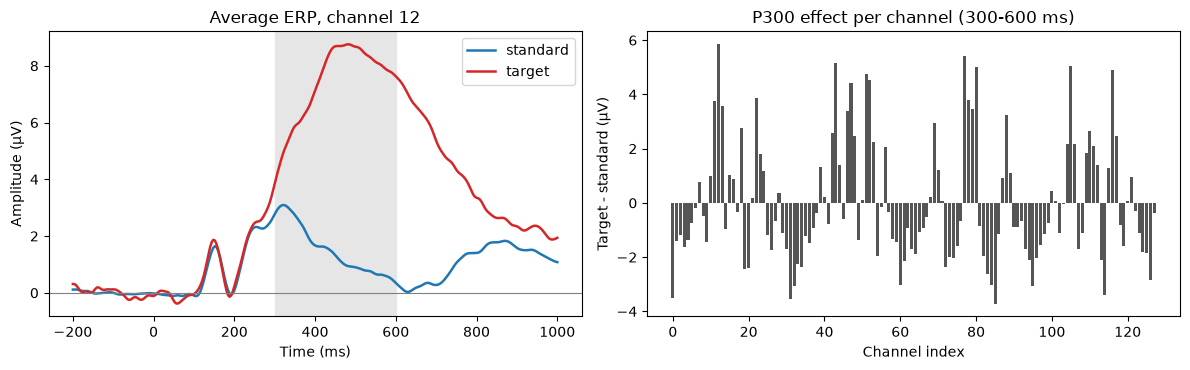

In [3]:
# Kiểm tra nhanh: ERP trung bình target vs standard ở kênh có hiệu ứng P300 mạnh nhất (300-600 ms)
win = (times >= 0.3) & (times <= 0.6)
diff = X[y == 1][:, :, win].mean((0, 2)) - X[y == 0][:, :, win].mean((0, 2))
best_ch = int(np.argmax(diff))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ax = axes[0]
for label, color, name in [(0, "#1f77b4", "standard"), (1, "#d62728", "target")]:
    ax.plot(times * 1000, X[y == label, best_ch].mean(0), color=color, lw=1.8, label=name)
ax.axvspan(300, 600, color="0.9", zorder=0)
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="Time (ms)", ylabel="Amplitude (µV)", title=f"Average ERP, channel {best_ch}")
ax.legend()

axes[1].bar(np.arange(len(diff)), diff, color="#555555")
axes[1].set(xlabel="Channel index", ylabel="Target - standard (µV)",
            title="P300 effect per channel (300-600 ms)")
fig.tight_layout()
plt.show()

## 2. Kiến trúc EEGNet

| Khối | Lớp | Ý nghĩa |
|---|---|---|
| 1 | Conv2D (1 × 125), F1 = 8 | Bộ lọc thời gian dài 0,5 s, học các dải tần |
| 1 | DepthwiseConv2D (128 × 1), D = 2, max-norm 1 | Bộ lọc không gian cho từng bộ lọc thời gian (giống CSP/xDAWN) |
| 1 | BN → ELU → AvgPool (1 × 4) → Dropout 0,5 | Giảm mẫu 250 → 62,5 Hz |
| 2 | SeparableConv2D (1 × 16), F2 = 16 | Tổng hợp thời gian ~250 ms |
| 2 | BN → ELU → AvgPool (1 × 8) → Dropout 0,5 | |
| Ra | Flatten → Linear (2 lớp), max-norm 0,25 | |

Mất cân bằng lớp được xử lý bằng **cross-entropy có trọng số lớp** (tương đương `class_weight="balanced"` ở V5).

In [4]:
model = EEGNet(n_channels=X.shape[1], n_times=X.shape[2])
print(model)
print(f"\nSố tham số huấn luyện: {count_parameters(model):,}")

x = torch.zeros(1, 1, X.shape[1], X.shape[2])
for name, layer in [("temporal", model.temporal), ("spatial", model.spatial),
                    ("block1_rest", model.block1_rest), ("block2", model.block2)]:
    x = layer(x)
    print(f"{name:12s} -> {tuple(x.shape)}")

EEGNet(
  (temporal): Sequential(
    (0): Conv2d(1, 8, kernel_size=(1, 125), stride=(1, 1), padding=(0, 62), bias=False)
    (1): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (spatial): Conv2d(8, 16, kernel_size=(128, 1), stride=(1, 1), groups=8, bias=False)
  (block1_rest): Sequential(
    (0): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (1): ELU(alpha=1.0)
    (2): AvgPool2d(kernel_size=(1, 4), stride=(1, 4), padding=0)
    (3): Dropout(p=0.5, inplace=False)
  )
  (block2): Sequential(
    (0): Conv2d(16, 16, kernel_size=(1, 16), stride=(1, 1), padding=(0, 8), groups=16, bias=False)
    (1): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ELU(alpha=1.0)
    (4): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (5): Dropout(p=0.5, inplace=False)
  )
  (classifier): Linear(in_features=

## 3. Huấn luyện thử trên một lần chia theo người

Giữ khoảng 20% **số người** làm tập test (`GroupShuffleSplit`, không người nào vừa ở train vừa ở test), phần còn lại tách 15% làm validation cho early stopping (dừng khi val loss không giảm sau 15 epoch). Bước này chỉ để xem đường cong học; số liệu chính thức là cross-validation ở mục 4.

In [5]:
from sklearn.model_selection import GroupShuffleSplit

EPOCHS, PATIENCE, BATCH_SIZE, LR = 50, 15, 64, 1e-3   # giống lệnh CLI chính thức

idx = np.arange(len(y))
if len(np.unique(groups)) >= 5:
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_SEED)
    tr_idx, te_idx = next(gss.split(idx, y, groups))
else:  # 1 người: chỉ có thể chia theo trial
    tr_idx, te_idx = train_test_split(idx, test_size=0.2, stratify=y, random_state=RANDOM_SEED)
tr_idx, va_idx = train_test_split(tr_idx, test_size=0.15, stratify=y[tr_idx], random_state=RANDOM_SEED)
print(f"Train {len(tr_idx)} / val {len(va_idx)} / test {len(te_idx)} trial; "
      f"người ở test: {len(np.unique(groups[te_idx]))}, giao train-test: "
      f"{len(np.intersect1d(groups[tr_idx], groups[te_idx]))}")

model, history, scale = train_eegnet(X[tr_idx], y[tr_idx], X[va_idx], y[va_idx],
                                     epochs=EPOCHS, patience=PATIENCE, batch_size=BATCH_SIZE,
                                     lr=LR, device=DEVICE, verbose=True)
probs_te = predict_proba(model, X[te_idx], scale)
pd.Series(compute_metrics(y[te_idx], probs_te)).round(3).to_frame("hold-out test (unseen subjects)")

Train 14795 / val 2611 / test 4472 trial; người ở test: 8, giao train-test: 0


  epoch   0  train 0.4091  val 0.3225  AUC 0.944  BAcc 0.889


  epoch  10  train 0.2071  val 0.2026  AUC 0.976  BAcc 0.919


  epoch  20  train 0.1657  val 0.1887  AUC 0.982  BAcc 0.927


  epoch  30  train 0.1536  val 0.1558  AUC 0.985  BAcc 0.939


  epoch  40  train 0.1398  val 0.1674  AUC 0.984  BAcc 0.933


  epoch  49  train 0.1288  val 0.1627  AUC 0.985  BAcc 0.941


,hold-out test (unseen subjects)
balanced_accuracy,0.942
roc_auc,0.986
pr_auc,0.917
f1_macro,0.890
f1_target,0.813
sensitivity,0.941
specificity,0.943


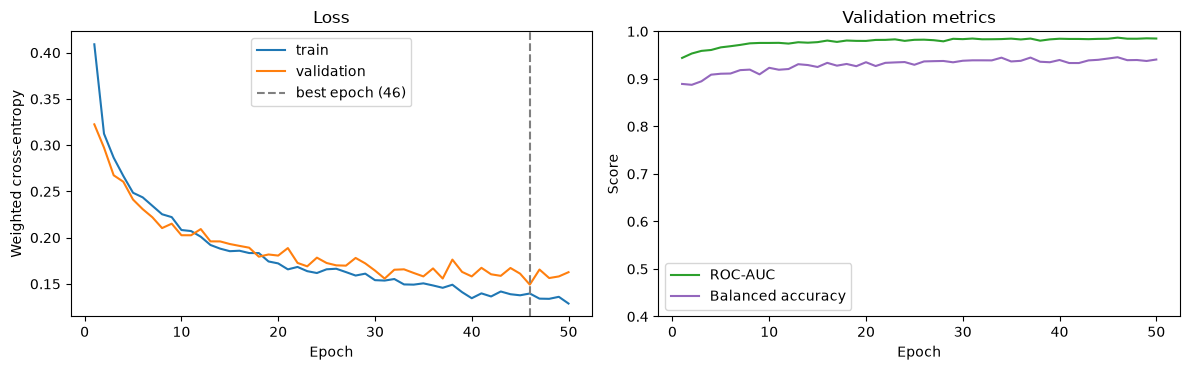

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
ep = np.arange(1, len(history["train_loss"]) + 1)
axes[0].plot(ep, history["train_loss"], label="train", color="#1f77b4")
axes[0].plot(ep, history["val_loss"], label="validation", color="#ff7f0e")
best_ep = int(np.argmin(history["val_loss"])) + 1
axes[0].axvline(best_ep, ls="--", color="0.5", label=f"best epoch ({best_ep})")
axes[0].set(xlabel="Epoch", ylabel="Weighted cross-entropy", title="Loss")
axes[0].legend()
axes[1].plot(ep, history["val_auc"], label="ROC-AUC", color="#2ca02c")
axes[1].plot(ep, history["val_bacc"], label="Balanced accuracy", color="#9467bd")
axes[1].set(xlabel="Epoch", ylabel="Score", title="Validation metrics", ylim=(0.4, 1.0))
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. Cross-validation (giống V5)

- ≥ 5 người → `GroupKFold(5)`: người ở tập test không xuất hiện khi huấn luyện (đánh giá liên người, không rò rỉ).
- 1 người → `StratifiedKFold(5)`.

Trong mỗi fold: tách 15% tập train làm validation cho early stopping; hệ số chuẩn hóa tính trên tập train của fold.

Mặc định ô dưới **đọc kết quả của script CLI** (`eegnet_folds_real.csv`, `eegnet_oof_real.npz`) nếu có và khớp dữ liệu đang nạp; nếu không có thì chạy lại CV.

In [7]:
RERUN_CV = False
folds_csv = TABLE_DIR / f"eegnet_folds_{DATA_TAG}.csv"
oof_npz = TABLE_DIR / f"eegnet_oof_{DATA_TAG}.npz"

loaded = False
if not RERUN_CV and folds_csv.exists() and oof_npz.exists():
    saved = np.load(oof_npz)
    if len(saved["y"]) == len(y) and np.array_equal(saved["y"], y):
        fold_df, oof_probs = pd.read_csv(folds_csv), saved["oof_probs"]
        loaded = True
        print(f"Đọc kết quả CV đã lưu từ script: {folds_csv.relative_to(ROOT)}, {oof_npz.relative_to(ROOT)}")
if not loaded:
    fold_df, oof_probs, histories = cross_validate(X, y, groups, n_splits=5, epochs=EPOCHS,
                                                   patience=PATIENCE, batch_size=BATCH_SIZE, lr=LR,
                                                   device=DEVICE)
fold_df.round(3)

Đọc kết quả CV đã lưu từ script: results\tables\eegnet_folds_real.csv, results\tables\eegnet_oof_real.npz


,fold,n_test,epochs_run,balanced_accuracy,roc_auc,pr_auc,f1_macro,f1_target,sensitivity,specificity
0,1,4033,48,0.884,0.968,0.867,0.883,0.799,0.799,0.968
1,2,4269,50,0.922,0.974,0.890,0.876,0.790,0.904,0.941
2,3,4527,49,0.915,0.974,0.891,0.820,0.706,0.945,0.885
3,4,4523,50,0.928,0.980,0.913,0.871,0.785,0.925,0.930
4,5,4526,50,0.886,0.954,0.804,0.836,0.722,0.846,0.926


In [8]:
summary = summarize("EEGNet", fold_df, y, oof_probs)
summary_df = pd.DataFrame([summary])

if not loaded:  # chỉ ghi bảng khi CV được chạy trong notebook (tránh ghi đè kết quả script)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)
    out_csv = TABLE_DIR / f"eegnet_metrics_{DATA_TAG}.csv"
    summary_df.to_csv(out_csv, index=False)
    print(f"Đã lưu: {out_csv.relative_to(ROOT)}")

cols = ["model", "balanced_accuracy_mean", "roc_auc_mean", "pr_auc_mean",
        "f1_macro_mean", "sensitivity_mean", "specificity_mean"]
baseline_csv = TABLE_DIR / "baseline_metrics.csv"
table = summary_df[cols]
if baseline_csv.exists():
    table = pd.concat([pd.read_csv(baseline_csv)[cols], table], ignore_index=True)
if DATA_TAG != "real" or len(np.unique(groups)) < 39:
    print("Lưu ý: baseline V5 dùng 39 người với GroupKFold; dòng EEGNet ở đây KHÔNG cùng tập dữ liệu, "
          "không so sánh trực tiếp.")
table.set_index("model").round(3)

,balanced_accuracy_mean,roc_auc_mean,pr_auc_mean,f1_macro_mean,sensitivity_mean,specificity_mean
model,,,,,,
Dummy,0.497,0.497,0.134,0.497,0.127,0.867
LDA,0.815,0.947,0.791,0.835,0.659,0.971
Logistic Regression,0.874,0.946,0.791,0.816,0.841,0.908
RBF SVM,0.799,0.946,0.791,0.824,0.625,0.973
Random Forest,0.638,0.907,0.652,0.678,0.289,0.988
EEGNet,0.907,0.970,0.873,0.857,0.884,0.930


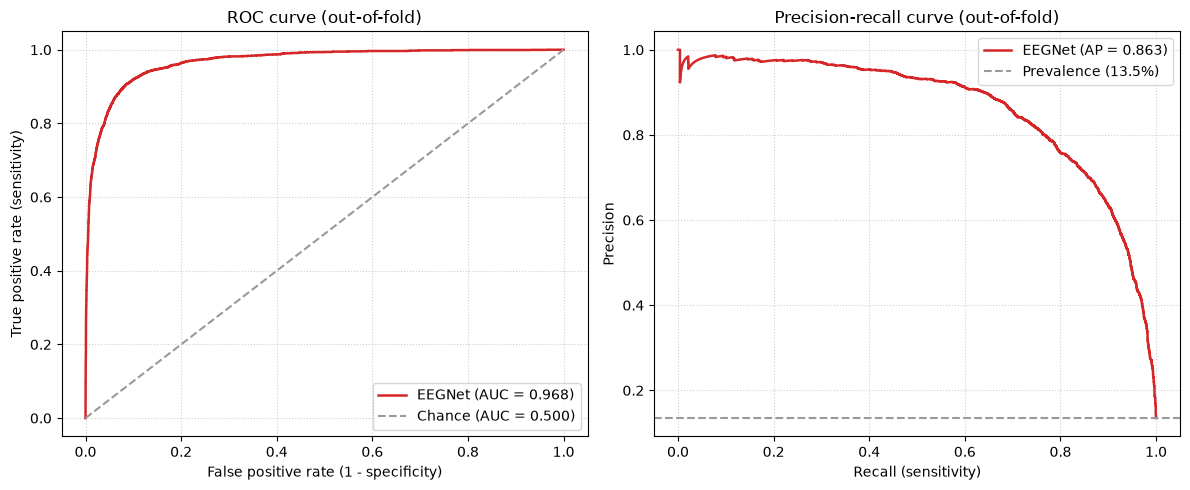

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fpr, tpr, _ = roc_curve(y, oof_probs)
axes[0].plot(fpr, tpr, color="#d62728", lw=1.8, label=f"EEGNet (AUC = {roc_auc_score(y, oof_probs):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="#999999", label="Chance (AUC = 0.500)")
axes[0].set(xlabel="False positive rate (1 - specificity)", ylabel="True positive rate (sensitivity)",
            title="ROC curve (out-of-fold)")
axes[0].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y, oof_probs)
axes[1].plot(rec, prec, color="#d62728", lw=1.8, label=f"EEGNet (AP = {average_precision_score(y, oof_probs):.3f})")
axes[1].axhline(y.mean(), ls="--", color="#999999", label=f"Prevalence ({y.mean():.1%})")
axes[1].set(xlabel="Recall (sensitivity)", ylabel="Precision", title="Precision-recall curve (out-of-fold)")
axes[1].legend(loc="upper right")
for ax in axes:
    ax.grid(True, ls=":", alpha=0.6)
fig.tight_layout()

if not loaded:  # hình chính thức do script lưu; chỉ lưu khi CV chạy trong notebook
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIG_DIR / f"eegnet_roc_pr_{DATA_TAG}.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Giải thích mô hình: saliency map

Saliency = |∂ logit(target) / ∂ đầu vào|, lấy trung bình trên các trial target. Nếu mô hình học đúng P300, độ nhạy sẽ tập trung ở **300–600 ms** và ở các kênh có hiệu ứng P300 mạnh (hình ở mục 1).

- **(a) Hold-out theo người** (mô hình ở mục 3, trial target của những người chưa gặp khi huấn luyện): chỉ hiển thị, không lưu.
- **(b) Kết quả chính thức** của script (mô hình tham chiếu, `eegnet_saliency_real.npz`): dùng trong báo cáo, kèm tên kênh.

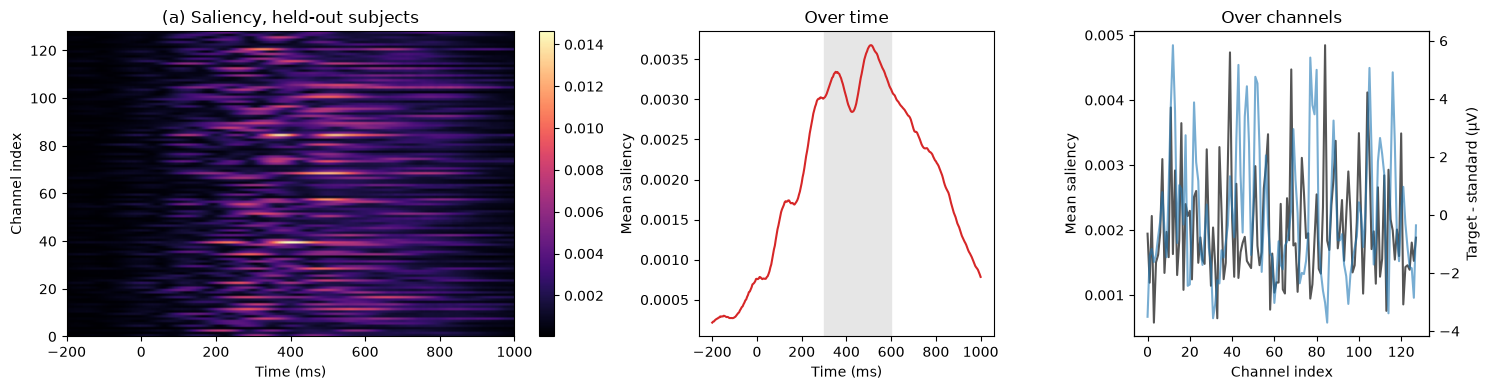

Đỉnh saliency theo thời gian: 508 ms
Tỉ lệ saliency trong 300-600 ms: 40.5% (cửa sổ chiếm 24.9% epoch)
Tương quan saliency theo kênh với hiệu ứng P300: r = 0.15


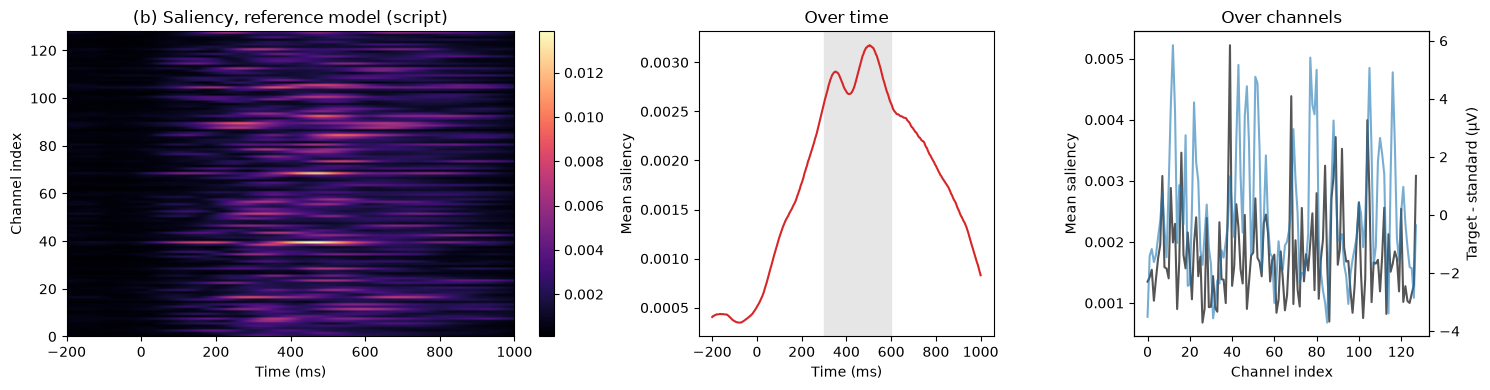

Đỉnh saliency theo thời gian: 504 ms
Tỉ lệ saliency trong 300-600 ms: 40.2% (cửa sổ chiếm 24.9% epoch)
Tương quan saliency theo kênh với hiệu ứng P300: r = 0.32
Top-10 kênh theo saliency: C1, FCC3h, CCP3h, FCC4h, FFC2h, Oz, PPO10h, FCz, C3, CCP2h


In [10]:
sal = saliency_map(model, X[te_idx][y[te_idx] == 1], scale)


def show_saliency(sal, title):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1.2, 1.2]})
    im = axes[0].imshow(sal, aspect="auto", cmap="magma", origin="lower",
                        extent=[times[0] * 1000, times[-1] * 1000, 0, sal.shape[0]])
    axes[0].set(xlabel="Time (ms)", ylabel="Channel index", title=title)
    fig.colorbar(im, ax=axes[0], fraction=0.04)
    axes[1].plot(times * 1000, sal.mean(0), color="#d62728")
    axes[1].axvspan(300, 600, color="0.9", zorder=0)
    axes[1].set(xlabel="Time (ms)", ylabel="Mean saliency", title="Over time")
    axes[2].plot(sal.mean(1), color="#555555", label="saliency")
    ax2 = axes[2].twinx()
    ax2.plot(diff, color="#1f77b4", alpha=0.6, label="P300 effect")
    axes[2].set(xlabel="Channel index", ylabel="Mean saliency", title="Over channels")
    ax2.set_ylabel("Target - standard (µV)")
    fig.tight_layout()
    plt.show()
    win_ = (times >= 0.3) & (times <= 0.6)
    print(f"Đỉnh saliency theo thời gian: {times[np.argmax(sal.mean(0))] * 1000:.0f} ms")
    print(f"Tỉ lệ saliency trong 300-600 ms: {sal[:, win_].sum() / sal.sum():.1%} "
          f"(cửa sổ chiếm {win_.mean():.1%} epoch)")
    print(f"Tương quan saliency theo kênh với hiệu ứng P300: r = {np.corrcoef(sal.mean(1), diff)[0, 1]:.2f}")


show_saliency(sal, "(a) Saliency, held-out subjects")

sal_npz = TABLE_DIR / f"eegnet_saliency_{DATA_TAG}.npz"
if sal_npz.exists():
    s = np.load(sal_npz)
    show_saliency(s["saliency"], "(b) Saliency, reference model (script)")
    if len(s["ch_names"]):
        names = list(s["ch_names"])
        top = np.argsort(s["saliency"].mean(1))[::-1][:10]
        print("Top-10 kênh theo saliency:", ", ".join(names[k] for k in top))

## 6. Ghi chú

- Lệnh chính thức (GPU, khoảng 25–50 phút trên RTX 4060): `python src/dl/train_eegnet.py --save --batch-size 64 --epochs 50`. Script lưu `eegnet_metrics_real.csv`, `eegnet_folds_real.csv`, `eegnet_oof_real.npz`, `eegnet_saliency_real.npz`, `ml_vs_dl_comparison.csv` và các hình `eegnet_roc_pr_real.png`, `eegnet_saliency_real.png`, `ml_vs_dl_comparison.png`.
- Ngưỡng quyết định là 0,5 (giống V5). Do dùng trọng số lớp, mô hình thiên về độ nhạy (sensitivity) cao hơn độ đặc hiệu (specificity).
- Thử nhanh: `REAL_SUBJECTS = ["sub-01"]` (StratifiedKFold, không so sánh được với V5) hoặc `python src/dl/train_eegnet.py --synthetic`.